# 📚 Analysis of Book Publication Data

Exploratory analysis of a dataset of 1,070 books: publishing year, genre, language, ratings, sales and publisher revenue. The notebook cleans the data, explores what sells and who earns the most, and tests whether famous authors sell more than intermediate ones.

See the [README](README.md) for the full context.

## 1. Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load the data

In [2]:
df = pd.read_csv("Data/Books_Data_Clean.csv")

In [3]:
df

,index,Publishing Year,Book Name,Author,language_code,Author_Rating,Book_average_rating,Book_ratings_count,genre,gross sales,publisher revenue,sale price,sales rank,Publisher,units sold
0,0,1975.0,Beowulf,"Unknown, Seamus Heaney",en-US,Novice,3.42,155903,genre fiction,34160.00,20496.000,4.88,1,HarperCollins Publishers,7000
1,1,1987.0,Batman: Year One,"Frank Miller, David Mazzucchelli, Richmond Lew...",eng,Intermediate,4.23,145267,genre fiction,12437.50,7462.500,1.99,2,HarperCollins Publishers,6250
2,2,2015.0,Go Set a Watchman,Harper Lee,eng,Novice,3.31,138669,genre fiction,47795.00,28677.000,8.69,3,"Amazon Digital Services, Inc.",5500
3,3,2008.0,When You Are Engulfed in Flames,David Sedaris,en-US,Intermediate,4.04,150898,fiction,41250.00,24750.000,7.50,3,Hachette Book Group,5500
4,4,2011.0,Daughter of Smoke & Bone,Laini Taylor,eng,Intermediate,4.04,198283,genre fiction,37952.50,22771.500,7.99,4,Penguin Group (USA) LLC,4750
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1065,1065,2014.0,Gray Mountain,John Grisham,eng,Intermediate,3.52,37379,nonfiction,104.94,62.964,0.99,1268,"Amazon Digital Services, Inc.",106
1066,1066,1989.0,The Power of One,Bryce Courtenay,eng,Excellent,4.34,57312,genre fiction,846.94,508.164,7.99,1270,Random House LLC,106
1067,1067,1930.0,The Maltese Falcon,Dashiell Hammett,eng,Intermediate,3.92,58742,genre fiction,846.94,508.164,7.99,1271,Hachette Book Group,106
1068,1068,2011.0,Night Road,Kristin Hannah,en-US,Excellent,4.17,58028,genre fiction,104.94,62.964,0.99,1272,"Amazon Digital Services, Inc.",106


## 3. Data quality

Types, missing values and summary statistics.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1070 entries, 0 to 1069
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   index                1070 non-null   int64  
 1   Publishing Year      1069 non-null   float64
 2   Book Name            1047 non-null   str    
 3   Author               1070 non-null   str    
 4   language_code        1017 non-null   str    
 5   Author_Rating        1070 non-null   str    
 6   Book_average_rating  1070 non-null   float64
 7   Book_ratings_count   1070 non-null   int64  
 8   genre                1070 non-null   str    
 9   gross sales          1070 non-null   float64
 10  publisher revenue    1070 non-null   float64
 11  sale price           1070 non-null   float64
 12  sales rank           1070 non-null   int64  
 13  Publisher            1070 non-null   str    
 14  units sold           1070 non-null   int64  
dtypes: float64(5), int64(4), str(6)
memory usage: 223

In [5]:
df.isna().sum()

index                   0
Publishing Year         1
Book Name              23
Author                  0
language_code          53
Author_Rating           0
Book_average_rating     0
Book_ratings_count      0
genre                   0
gross sales             0
publisher revenue       0
sale price              0
sales rank              0
Publisher               0
units sold              0
dtype: int64

In [6]:
df.describe()

,index,Publishing Year,Book_average_rating,Book_ratings_count,gross sales,publisher revenue,sale price,sales rank,units sold
count,1070.000000,1069.000000,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000,1070.000000
mean,534.500000,1971.377923,4.007000,94909.913084,1856.622944,843.281030,4.869561,611.652336,9676.980374
std,309.026698,185.080257,0.247244,31513.242518,3936.924240,2257.596743,3.559919,369.849830,15370.571306
min,0.000000,-560.000000,2.970000,27308.000000,104.940000,0.000000,0.990000,1.000000,106.000000
25%,267.250000,1985.000000,3.850000,70398.000000,372.465000,0.000000,1.990000,287.500000,551.250000
50%,534.500000,2003.000000,4.015000,89309.000000,809.745000,273.078000,3.990000,595.500000,3924.000000
75%,801.750000,2010.000000,4.170000,113906.500000,1487.957500,721.180500,6.990000,932.500000,5312.250000
max,1069.000000,2016.000000,4.770000,206792.000000,47795.000000,28677.000000,33.860000,1273.000000,61560.000000


Keep books published from **1900 onwards** and drop rows **without a book name**, then check for duplicates.

In [7]:
df = df[df["Publishing Year"] >= 1900]

In [8]:
df.isna().sum()

index                   0
Publishing Year         0
Book Name              21
Author                  0
language_code          49
Author_Rating           0
Book_average_rating     0
Book_ratings_count      0
genre                   0
gross sales             0
publisher revenue       0
sale price              0
sales rank              0
Publisher               0
units sold              0
dtype: int64

In [9]:
df = df[~df["Book Name"].isna()]  # ~ negates the condition: keep rows that have a book name

In [10]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
1065    False
1066    False
1067    False
1068    False
1069    False
Length: 988, dtype: bool

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.nunique()

index                  988
Publishing Year        101
Book Name              987
Author                 669
language_code            8
Author_Rating            4
Book_average_rating    133
Book_ratings_count     983
genre                    4
gross sales            774
publisher revenue      570
sale price             143
sales rank             818
Publisher                9
units sold             470
dtype: int64

## 4. Distribution by publishing year

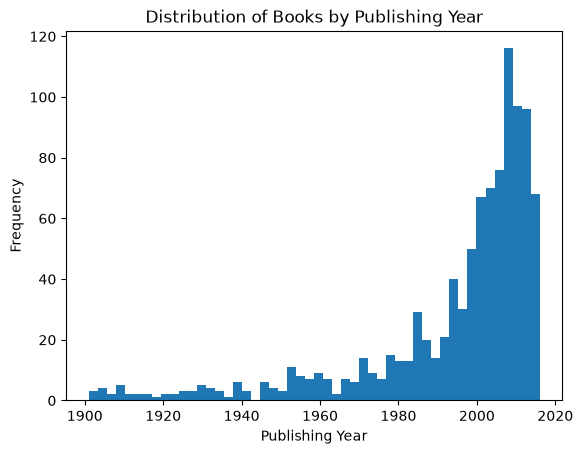

In [13]:
plt.hist(df['Publishing Year'], bins=50)
plt.xlabel('Publishing Year')
plt.ylabel('Frequency')
plt.title('Distribution of Books by Publishing Year')
plt.show()

## 5. Genres

`genre fiction` and `fiction` describe the same category, so they are merged.

In [14]:
df["genre"].value_counts()

genre
genre fiction    759
nonfiction       160
fiction           54
children          15
Name: count, dtype: int64

In [15]:
# Standardize genres: 'genre fiction' and 'fiction' are the same category
df['genre'] = df['genre'].apply(lambda genre: 'fiction' if genre == 'genre fiction' else genre)

In [16]:
df["genre"].value_counts()

genre
fiction       813
nonfiction    160
children       15
Name: count, dtype: int64

<Axes: title={'center': 'Books by Genre'}, xlabel='genre'>

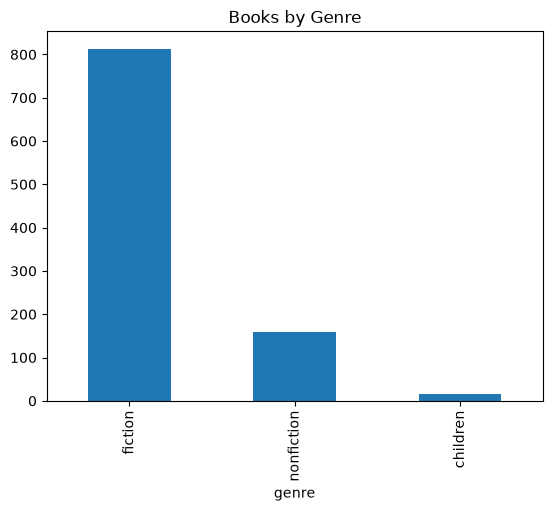

In [17]:
df["genre"].value_counts().plot(kind="bar", title="Books by Genre")

## 6. Ratings by author and genre

In [18]:
df.groupby("Author")["Book_average_rating"].mean().sort_values(ascending=False)

Author
Bill Watterson                  4.650000
Bill Watterson, G.B. Trudeau    4.610000
J.R.R. Tolkien                  4.590000
George R.R. Martin              4.560000
Sarah J. Maas                   4.526000
                                  ...   
Chetan Bhagat                   3.273333
Audrey Niffenegger              3.230000
Herman Koch, Sam Garrett        3.220000
P.D. James                      3.210000
Sue Monk Kidd                   3.100000
Name: Book_average_rating, Length: 669, dtype: float64

Text(0.5, 1.0, 'Ratings Count by Genre')

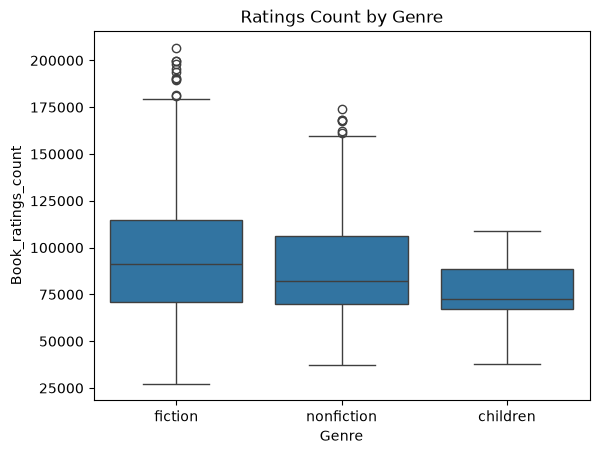

In [19]:
sns.boxplot(x="genre", y="Book_ratings_count", data=df)
plt.xlabel("Genre")
plt.title("Ratings Count by Genre")

Text(0.5, 1.0, 'Average Rating by Genre')

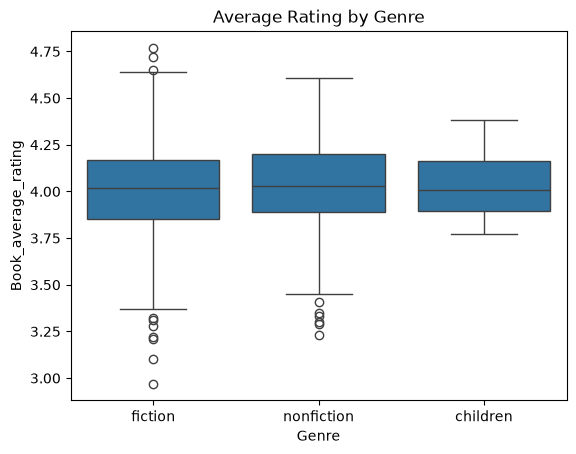

In [20]:
sns.boxplot(x="genre", y="Book_average_rating", data=df)
plt.xlabel("Genre")
plt.title("Average Rating by Genre")

## 7. Price vs. units sold

Text(0.5, 1.0, 'Sale Price vs. Units Sold')

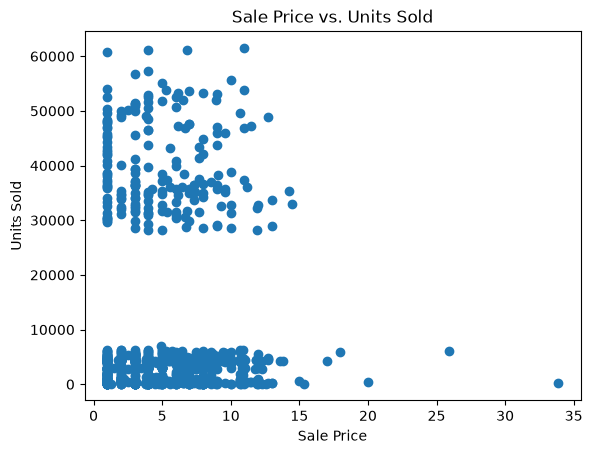

In [21]:
plt.scatter(df["sale price"], df["units sold"])
plt.xlabel("Sale Price")
plt.ylabel("Units Sold")
plt.title("Sale Price vs. Units Sold")

## 8. Languages

In [22]:
df["language_code"].value_counts()

language_code
eng      670
en-US    226
en-GB     29
en-CA      7
fre        4
spa        2
ara        2
nl         1
Name: count, dtype: int64

In [23]:
language_counts = df["language_code"].value_counts()

Text(0.5, 1.0, 'Books by Language Code')

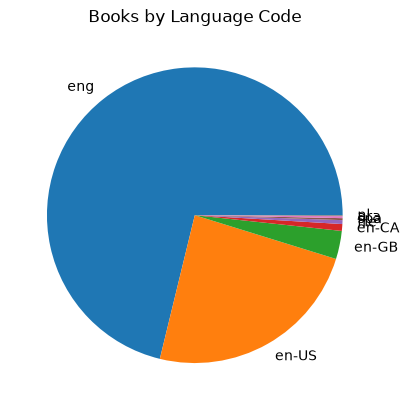

In [24]:
plt.pie(language_counts, labels=language_counts.index)
plt.title("Books by Language Code")

## 9. Revenue by publisher

In [25]:
df.groupby("Publisher ")["publisher revenue"].sum().sort_values(ascending=False)

Publisher 
Penguin Group (USA) LLC                 191581.104
Random House LLC                        174956.244
Amazon Digital Services,  Inc.          141767.772
HarperCollins Publishers                121769.814
Hachette Book Group                     107410.968
Simon and Schuster Digital Sales Inc     46858.206
Macmillan                                31249.830
HarperCollins Publishing                  2830.806
HarperCollins Christian Publishing        2135.670
Name: publisher revenue, dtype: float64

## 10. Author rating, popularity and sales

In [26]:
df["Author_Rating"].value_counts()

Author_Rating
Intermediate    576
Excellent       336
Famous           48
Novice           28
Name: count, dtype: int64

In [27]:
df.groupby("Author_Rating")["Book_ratings_count"].sum()

Author_Rating
Excellent       28158413
Famous           4718172
Intermediate    58406557
Novice           2444917
Name: Book_ratings_count, dtype: int64

Text(0.5, 1.0, 'Average Rating vs. Ratings Count')

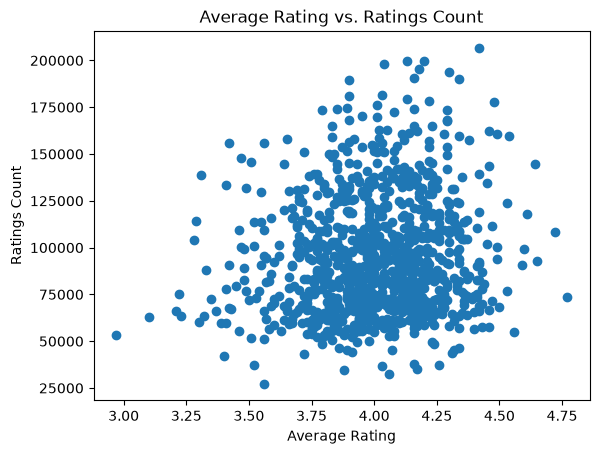

In [28]:
plt.scatter(df["Book_average_rating"], df["Book_ratings_count"])
plt.xlabel("Average Rating")
plt.ylabel("Ratings Count")
plt.title("Average Rating vs. Ratings Count")

Text(0.5, 1.0, 'Average Rating vs. Units Sold')

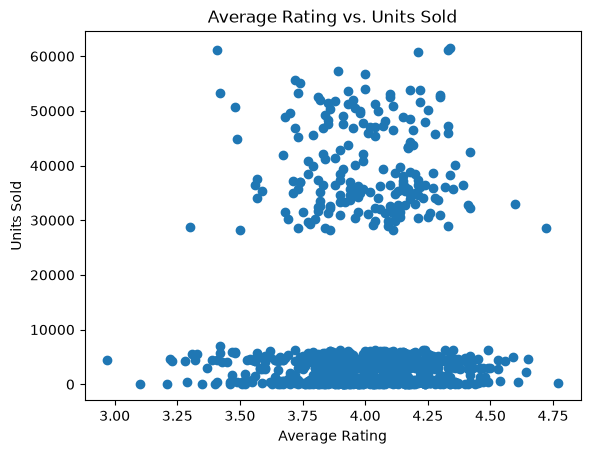

In [29]:
plt.scatter(df["Book_average_rating"], df["units sold"])
plt.xlabel("Average Rating")
plt.ylabel("Units Sold")
plt.title("Average Rating vs. Units Sold")

Text(0.5, 1.0, 'Average Rating vs. Units Sold (books under 10,000 units)')

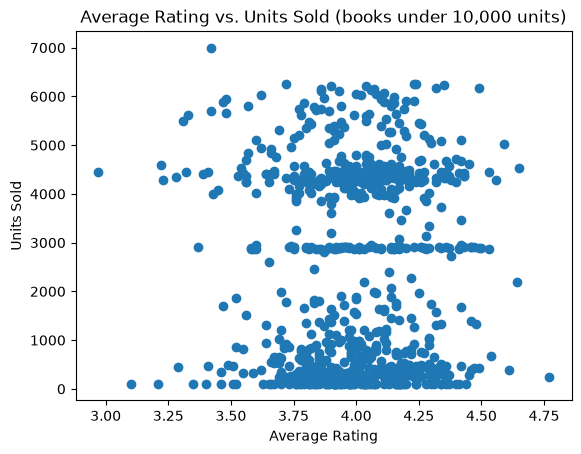

In [30]:
under_10k = df["units sold"] < 10000

plt.scatter(df[under_10k]["Book_average_rating"], df[under_10k]["units sold"])
plt.xlabel("Average Rating")
plt.ylabel("Units Sold")
plt.title("Average Rating vs. Units Sold (books under 10,000 units)")

## 11. Gross sales by author

In [31]:
df.groupby("Author")["gross sales"].sum()

Author
A.A. Milne, Ernest H. Shepard                       214.92
A.S.A. Harrison                                     784.16
Abbi Glines                                        2990.16
Adam Johnson                                        108.90
Adam Mansbach, Ricardo CortÃ©s                      113.85
                                                    ...   
William Styron                                      220.89
Yana Toboso, Tomo Kimura                           1366.86
Zadie Smith                                         167.31
Ø£Ø­Ù„Ø§Ù… Ù…Ø³ØªØºØ§Ù†Ù…ÙŠ, Ahlam Mosteghanemi    1200.10
Ø£Ø­Ù…Ø¯ Ù…Ø±Ø§Ø¯                                  1128.87
Name: gross sales, Length: 669, dtype: float64

## 12. Correlation between rating, popularity and revenue

In [32]:
df[["Book_average_rating",
   "Book_ratings_count",
   "gross sales",
   "sale price"]].corr()

,Book_average_rating,Book_ratings_count,gross sales,sale price
Book_average_rating,1.000000,0.120600,-0.042815,-0.015232
Book_ratings_count,0.120600,1.000000,0.489752,-0.067698
gross sales,-0.042815,0.489752,1.000000,0.269951
sale price,-0.015232,-0.067698,0.269951,1.000000


## 13. Sales by author rating and over time

<Axes: xlabel='Author_Rating', ylabel='units sold'>

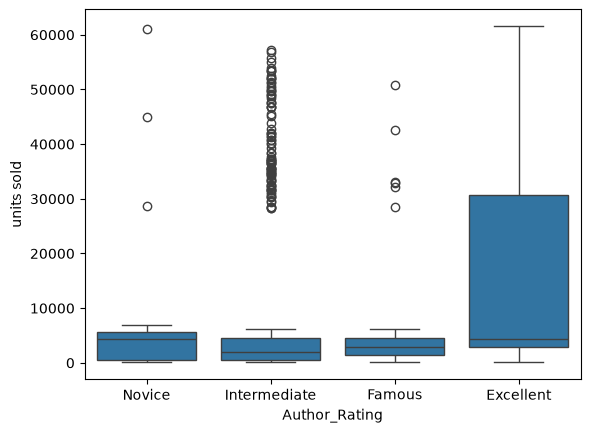

In [33]:
sns.boxplot(x="Author_Rating", y="units sold", data=df)

<Axes: title={'center': 'Units Sold by Publishing Year'}, xlabel='Publishing Year'>

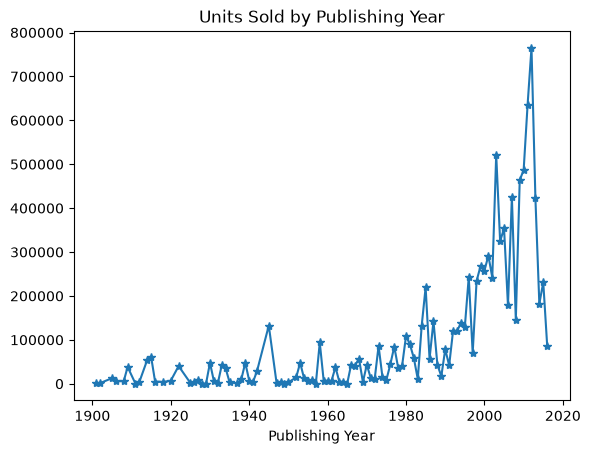

In [34]:
df.groupby("Publishing Year")["units sold"].sum().plot(kind="line", marker="*", title="Units Sold by Publishing Year")

## 14. Hypothesis test: do famous authors sell more?

- **H₀:** mean units sold are equal for *Famous* and *Intermediate* authors
- **H₁:** the means are different
- **Method:** Welch's t-test for independent samples (5% significance level)

In [35]:
import scipy.stats as stats

# Split the two groups
famous_sales = df[df["Author_Rating"] == "Famous"]["units sold"]
intermediate_sales = df[df["Author_Rating"] == "Intermediate"]["units sold"]

# Welch's t-test for independent samples (equal_var=False: does not assume equal variances)
t_stat, p_val = stats.ttest_ind(famous_sales, intermediate_sales, equal_var=False)

print(f"t-statistic: {t_stat:.4f}")
print(f"p-value: {p_val:.4f}")

t-statistic: -0.6595
p-value: 0.5121


## 15. Conclusions

- **Data quality:** after removing books published before 1900 and rows without a name, **988 of 1,070 books** remain, with no duplicates.
- **Genres:** fiction dominates the catalog with **813 of 988 books (≈ 82%)**, followed by nonfiction (160) and children (15).
- **Languages:** 8 language codes, almost all English variants.
- **Publishers:** Penguin Group (USA) LLC, Random House LLC and Amazon Digital Services lead in revenue.
- **Popularity vs. revenue:** ratings count has a **moderate positive correlation with gross sales (r ≈ 0.49)**, while the average rating barely relates to it (r ≈ −0.04).
- **Hypothesis test:** **t = −0.66, p = 0.51**. We cannot reject H₀: there is no evidence that *Famous* authors sell more units than *Intermediate* ones in this dataset.